# Lab 25.3: What Explanations Give Away

Run the cells from top to bottom; Section 4 invites you to change one setting. A target model sits behind an API. An attacker sends queries and trains a copy. We compare an API that returns only a decision with one that also returns TreeSHAP attributions, then try two defenses.

Data: synthetic (scikit-learn `make_classification`, 8 features), so that the experiment runs in about two minutes and nothing depends on a real person's data. This notebook reproduces Figure 25.2 of Chapter 25.

In [1]:
import numpy as np, warnings, time
import matplotlib.pyplot as plt
import shap
from sklearn.datasets import make_classification
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
warnings.filterwarnings("ignore"); T0 = time.time()
X, y = make_classification(n_samples=6000, n_features=8, n_informative=5, n_redundant=1, random_state=1)
T = GradientBoostingClassifier(n_estimators=200, max_depth=3, random_state=0).fit(X[:4000], y[:4000])
ex = shap.TreeExplainer(T)
print("target accuracy on held-out data: %.4f" % T.score(X[4000:], y[4000:]))
mu, cov = X.mean(0), np.cov(X.T)          # the attacker knows roughly where inputs lie
rng = np.random.default_rng(0)
Z = rng.multivariate_normal(mu, cov, 4000); tz = T.predict(Z)

target accuracy on held-out data: 0.9145


**Checkpoint 1:** target accuracy 0.9145.

## 1. Efficiency is a leak

SHAP attributions add up to the model's raw score (Chapter 8). So an API that shows a decision and its attributions also shows the exact score, even if the score itself is hidden.

In [2]:
q = Z[:3]; phi = ex.shap_values(q)
print("base + sum of attributions:", (ex.expected_value + phi.sum(1)).round(4))
print("model's raw score:          ", T.decision_function(q).round(4))

base + sum of attributions: [1.7422 0.2272 4.637 ]
model's raw score:           [1.7422 0.2272 4.637 ]


## 2. Copying the model with and without attributions

The label-only attacker trains a classifier on (query, decision). The attribution attacker trains one small regressor per feature to predict that feature's attribution, and adds them up. Agreement is measured on 4,000 fresh points.

In [3]:
def attack(n, mode, reps=5):
    out = []
    for _ in range(reps):
        Q = rng.multivariate_normal(mu, cov, n); lab = T.predict(Q)
        if mode == "label":
            if len(set(lab)) < 2: out.append(np.mean(tz == lab[0])); continue
            out.append(np.mean(GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=0).fit(Q, lab).predict(Z) == tz)); continue
        phi = ex.shap_values(Q)
        if mode == "top3_rounded":          # defense: only the three largest attributions, rounded to 0.5
            keep = np.zeros_like(phi, dtype=bool); idx = np.argsort(-np.abs(phi), 1)[:, :3]
            np.put_along_axis(keep, idx, True, 1); phi = np.where(keep, np.round(phi * 2) / 2, 0.0)
        ms = [GradientBoostingRegressor(n_estimators=60, max_depth=2, random_state=0).fit(Q, phi[:, j]) for j in range(8)]
        out.append(np.mean(((ex.expected_value + sum(m.predict(Z) for m in ms)) > 0) == tz))
    return np.mean(out)
NS = [10, 25, 50, 100, 200, 400, 800, 1600]
res = {m: [attack(n, m) for n in NS] for m in ["label", "attributions", "top3_rounded"]}
for m, v in res.items(): print(m.ljust(14), np.round(v, 3))

label          [0.648 0.741 0.762 0.809 0.85  0.874 0.896 0.908]
attributions   [0.746 0.816 0.858 0.88  0.898 0.902 0.908 0.914]
top3_rounded   [0.7   0.806 0.842 0.859 0.884 0.892 0.897 0.899]


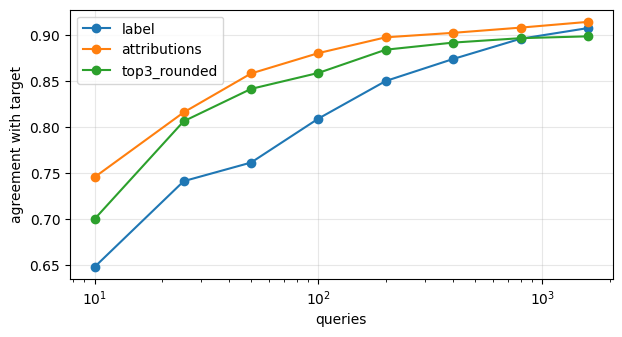

In [4]:
plt.figure(figsize=(7, 3.5))
for m, v in res.items(): plt.plot(NS, v, marker="o", label=m)
plt.xscale("log"); plt.xlabel("queries"); plt.ylabel("agreement with target"); plt.legend(); plt.grid(alpha=.3); plt.show()

**Checkpoint 2:** with 50 queries the attribution copy agrees with the target on about 0.86 of fresh points; the label-only copy needs about 400 queries to reach a similar level (about 0.87). The `top3_rounded` line shows how much a coarser explanation gives away; compare it with the other two lines and write down what you see.

## 3. Membership: do explanations reveal who was in the training data?

Shokri, Strobel and Zick (2021) found that some explanations leak membership. A crude test here: is the spread of attributions different for training points and unseen points? An AUC near 0.5 means this simple signal leaks little for this model; it does not prove that no attack works.

In [5]:
from sklearn.metrics import roc_auc_score
inn, out = X[:1000], X[4000:5000]
s_in = np.abs(ex.shap_values(inn)).sum(1); s_out = np.abs(ex.shap_values(out)).sum(1)
print("AUC of attribution size as a membership signal: %.3f" % roc_auc_score(np.r_[np.ones(1000), np.zeros(1000)], np.r_[s_in, s_out]))
print("minutes: %.1f" % ((time.time() - T0) / 60))

AUC of attribution size as a membership signal: 0.507
minutes: 0.5


## 4. Your turn

Change the number of features kept in the `top3_rounded` defense to 1 and to 5 (edit the `[:, :3]`), rerun Section 2, and record the agreement at 50 and 400 queries.

## What to hand in

The agreement table for the three arms (and your variant), the membership AUC, and a half-page note to a product owner: what the explanation API should return to customers, to partners and to internal analysts, and what it costs in usefulness.